# TxLens — 마이데이터 거래내역 인텔리전스 에이전트

「KB AI 엘리트 교육」 최종 제출 노트북.

**이 노트북은 얇은 오케스트레이터다 (설계 결정 D-018).** 로직은 전부 `src/txlens/` 패키지에 있고
여기서는 그것을 import 해서 부르기만 한다. 셀 안에 파이프라인 로직을 다시 쓰지 않으므로
**노트북에 보이는 결과 = 실제 프로그램(CLI·화면)이 내는 결과**다. 코드를 봐야 하는 자리는
`inspect.getsource` 로 실제로 실행되는 소스를 그대로 보여 준다.

**API 키 없이 끝까지 돈다.** LLM 단계는 실호출 때 저장해 둔 판정(`data/gold/verdicts-*.json`)을
재생한다 — 발표 화면과 같은 경로다. 실호출은 CLI 로 한다(맨 아래 참고).

| 부 | 내용 | 절 |
| --- | --- | --- |
| 1부 | 정규화·분류 — 룰(head) + LLM(tail) + 사전 승격 루프 | 2~5 |
| 2부 | 패턴 탐지 — 구독 · 이상지출 · 이상거래 (결정론 통계 규칙) | 6 |
| 묶는 주장 | **"가맹점명을 못 묶으면 구독도 못 찾는다"** — §5.2 전이 실험 | 6 |


## 1. 준비 — 패키지 설치 · 합성 데이터 생성

저장소 루트에서 한 번: `pip install -r requirements.txt && pip install -e .`
합성 데이터는 커밋하지 않는다 — 시드 42 로 매번 같은 데이터가 재현된다(거래 8,969건 · 정답 동시 기록).

In [1]:
import inspect
import os
import time
from pathlib import Path

# 노트북은 notebooks/ 안에 있다 — 저장소 루트를 기준으로 경로를 잡는다
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import txlens

print("txlens 패키지:", Path(txlens.__file__).parent.relative_to(ROOT))

txlens 패키지: src/txlens


In [2]:
from txlens.generator.__main__ import main as generate

generate(["--seed", "42"])

시드 42 · 고객 30명 · 2026-03-01~2026-08-31
  거래 8969건 · 원본 표기 1218개 · 구독 90 · 이상지출 60 · 이상거래 34 · 오탐함정 60
  번들 57개 → /home/dev/projects/agent-study-project/data/synthetic


0

## 2. 그래프 구조 — 실제로 컴파일되는 LangGraph

(C) 하이브리드 구성의 8노드 그래프. 그림을 손으로 그리지 않고 `build_graph()` 가 컴파일한 것에서
뽑는다. 아래 셀은 **지금 컴파일한 그래프의 mermaid 원문이 커밋된 그림의 원문과 같은지** 먼저
대조한 뒤 그림을 띄운다 — 설계도와 구현이 어긋나면 여기서 `False` 가 나온다.

사전 v1 · 재생 판정 149개 (openai:gpt-4o-mini)
노드 8개 (실행 순서는 3절 로그)
커밋된 그림과 지금 그래프가 같은가: True


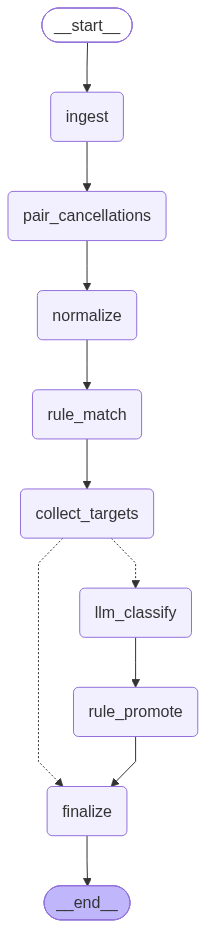

In [3]:
from IPython.display import Image, display

from txlens.agents.replay import ReplayClassifier, load_verdicts
from txlens.graph import build_graph
from txlens.rules import RuleMatcher, load_dictionary

VERDICTS = ROOT / "data/gold/verdicts-v1-gpt-4o-mini.json"
verdicts, model_name = load_verdicts(VERDICTS)
dictionary = load_dictionary()               # rules/v1.yaml
print(f"사전 v{dictionary.version} · 재생 판정 {len(verdicts)}개 ({model_name})")

graph_c = build_graph(matcher=RuleMatcher(dictionary), classifier=ReplayClassifier(verdicts))
nodes = [n for n in graph_c.get_graph().nodes if not n.startswith("__")]
print(f"노드 {len(nodes)}개 (실행 순서는 3절 로그)")

committed = (ROOT / "assets/diagrams/langgraph-c.mmd").read_text(encoding="utf-8")
live = graph_c.get_graph().draw_mermaid()
print("커밋된 그림과 지금 그래프가 같은가:", committed.strip() == live.strip())
display(Image(filename=str(ROOT / "assets/diagrams/langgraph-c.png"), width=360))

LLM 은 `llm_classify` 노드 **안에만** 있다(LangChain 1.0 `create_agent` · D-017). 그 노드를
열면 이렇게 생겼다 — 가드레일은 프롬프트 설정이 아니라 그래프의 노드다.

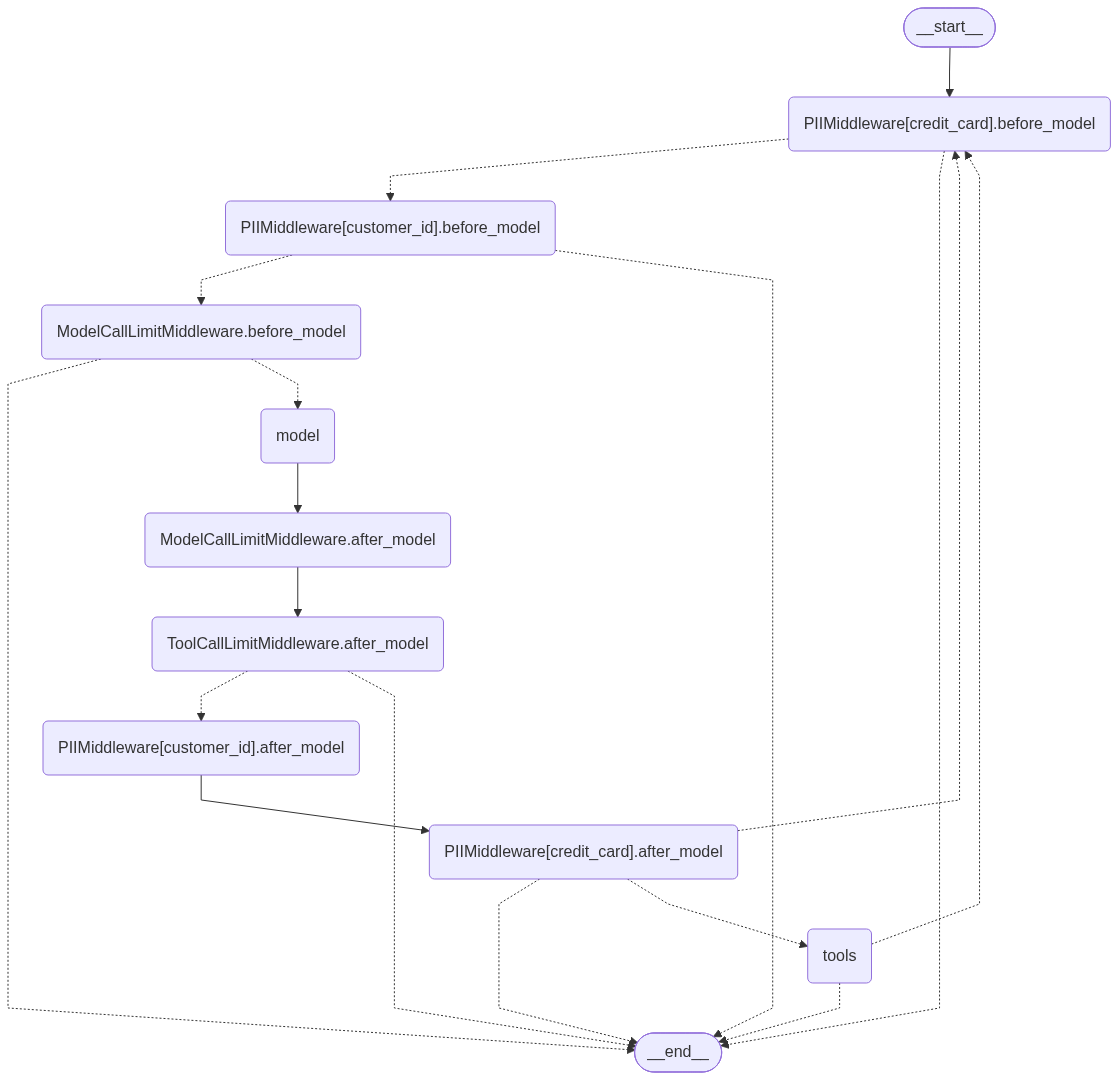

In [4]:
display(Image(filename=str(ROOT / "assets/diagrams/langgraph-agent.png"), width=420))

## 3. 그래프를 한 번 돌린다 — 노드별 실행 로그

`stream(stream_mode="updates")` 로 노드가 끝날 때마다 무엇을 썼는지 찍는다. 발표 화면 옆 칸의
로그(D-054)와 같은 스트림이다.

In [5]:
t0 = time.perf_counter()
final = {}
for chunk in graph_c.stream({"bundle_dir": str(ROOT / "data/synthetic/bundle")},
                            stream_mode="updates"):
    for node, update in chunk.items():
        final.update(update or {})
        sizes = {k: (len(v) if hasattr(v, "__len__") and not isinstance(v, str) else v)
                 for k, v in (update or {}).items() if k != "metrics"}
        print(f"[{time.perf_counter() - t0:5.2f}s] {node:<20} {sizes}")

m = final["metrics"]
print()
print(m.report())

[ 0.07s] ingest               {'raw': 8969}
[ 0.07s] pair_cancellations   {'pairings': 350}
[ 0.17s] normalize            {'normalized': 8969}


[ 0.20s] rule_match           {'matched': 8619}
[ 0.20s] collect_targets      {'llm_targets': 155}
[ 0.20s] llm_classify         {'llm_results': 149, 'llm_failed': 6, 'review_queue': 64}
[ 0.20s] rule_promote         {'rule_proposals': 34}
[ 0.21s] finalize             {'confirmed': 8619}

  실행  전체 8969건 → 분류 대상 8619건 (룰 확정 7262건)
        LLM 표기 155개 · 모델 호출 0회 (캐시 히트 149)
        LLM 이 모른다고 답함 9개 · 판정 실패 6개 · 검토 큐 64개 (사람 교정 0개)


## 4. 베이스라인 비교 — A 룰만 · B LLM만 · C 하이브리드

세 구성이 **같은 그래프 하나**를 돈다. 바뀌는 것은 사전과 분류기 둘뿐이다(D-025②).
A·C 는 여기서 다시 잰다. B 는 사전 없이 모든 표기를 LLM 에 보내는 구성이라 재생할 판정이 따로
없어 실호출 스냅샷(`data/gold/baselines-v1-*.json`)을 읽는다.

In [6]:
import json

from txlens.eval.harness import compare_table, run_baseline

res_a, met_a = run_baseline(label="A · 룰만", dictionary=dictionary)
res_c, met_c = run_baseline(label="C · 하이브리드(재생)", dictionary=dictionary,
                            classifier=ReplayClassifier(verdicts))
print(compare_table([(res_a, met_a), (res_c, met_c)]))

snap = json.loads((ROOT / "data/gold/baselines-v1-gpt-4o-mini.json").read_text(encoding="utf-8"))
b = next(r["result"] for r in snap if r["result"]["label"].startswith("B"))
print(f"\nB · LLM만(실호출 스냅샷)  거래 L2 {b['overall']['accuracy_l2']:.1%} · "
      f"커버리지 {b['overall']['coverage']:.1%}")

■ 베이스라인 비교

  베이스라인               거래 L2    표기 L2     커버리지     미매칭     PG   LLM표기    모델호출
  ──────────────────────────────────────────────────────────────────────────
  A · 룰만              93.0%    42.0%    84.3%    7.7%   8.0%       0       0
  C · 하이브리드(재생)       98.9%    86.4%    90.4%    1.6%   8.0%     155       0

  · 커버리지 + 미매칭 + PG마스킹 = 100%. PG마스킹은 **원리적 한계**라 줄지 않는다 (D-024②).
  · LLM 이 '모른다'고 답한 표기는 미매칭에 남는다 — 미분류를 커버리지로 세지 않는다.

B · LLM만(실호출 스냅샷)  거래 L2 85.6% · 커버리지 86.8%


**읽는 법.** B 는 커버리지가 높아도 거래 L2 정확도가 A 보다 낮다 — 사전 없이 LLM 만 쓰면 모르는
것을 **자신 있게 틀린다.** C 는 룰이 먼저 잡고 남은 꼬리만 LLM 에 보내 정확도와 호출 수를 함께
잡는다. 이 비교가 1부의 근거다. (B 는 실호출이라 재실행마다 ±3.6pp 움직인다 — D-048)

## 5. 사전 승격 루프 — LLM 판정이 사전으로 굳는다

C 를 한 번 돌리면 `rule_promote` 노드가 **별칭 후보**를 낸다. 사전이 이미 아는 브랜드의 새 표기만
자동으로 올리고(사전이 판정의 검증자), 새 브랜드는 사람 몫으로 남긴다(D-033). 다음 라운드는 커진
사전으로 돈다. 여기서는 저장된 판정을 재생한다.

In [7]:
from txlens.promote import rounds_table, run_rounds

reports = run_rounds("replay", dictionary=dictionary, replay=verdicts, max_rounds=3)
print(rounds_table(reports))

■ 승격 루프

  라운드          사전      키     미매칭표기   LLM표기    모델호출    거래 L2    표기 L2     미매칭     승격     덮는거래
  ──────────────────────────────────────────────────────────────────────────────────────────
  1            v1     65       155     155       0    98.9%    86.4%    1.6%     34       40
  2            v2     99       121     121       0    99.0%    88.6%    1.6%      0        0

  · 멈춘 이유: 고정점 — 승격할 후보가 없다
  · 미매칭 표기 155 → 121 (21.9% 감소) · 모델 호출 0 → 0
  · 승격은 정확도를 올리는 장치가 아니라 **호출을 줄이는** 장치다 — 거래 L2 가 함께 떨어지면 자동 승격이 오답을 굳힌 것이고, 그게 HITL 이 필요한 이유다.


재생은 라운드 2 에서 멈춘다. 그러나 **실호출로 5라운드를 돌리면 고정점이 없었다**(2,549호출 ·
사전 65→121키 · LLM 표기 155→98 · 호출 572→351). 재생 판정은 v1 사전에서 받은 답이라 커진 사전을
보지 못하기 때문이다. 승격 자체는 13/13 맞았고 오타가 롱테일이라 **끝내는 건 사람 판단**이다
(D-056). 사람 교정은 화면 S1(검토 큐)에서 한다.

## 6. 2부 패턴 탐지 + §5.2 전이 실험

탐지는 그래프 **밖**의 순수 함수다(D-035) — 같은 탐지기를 서로 다른 분류 결과 위에서 돌려야
"분류 품질이 탐지 품질을 좌우한다"를 잴 수 있다. LLM 은 쓰지 않는다.

In [8]:
from txlens.eval.transfer import run_transfer, transfer_table

rows = run_transfer(verdicts_path=VERDICTS)
print(transfer_table(rows))

■ §5.2 분류 → 탐지 전이 실험

  분류 단계                미묶음          구독 P/R        이상지출 P/R        이상거래 P/R     알림/월
  ─────────────────────────────────────────────────────────────────────────────────
  정규화만              100.0%  95.3%/56.2%      0.0%/0.0%      96.4%/79.4%         0.2
  A · 룰만             15.7%  94.7%/74.0%     63.2%/61.0%     97.1%/100.0%        0.5
  C · 하이브리드           9.6%  94.7%/74.0%     62.5%/67.8%     97.1%/100.0%        0.6
  정답 분류(상한)           8.0%  95.7%/90.4%     62.7%/71.2%     97.1%/100.0%        0.6

  · '미묶음' = 미매칭 + PG마스킹. 대표명이 없어 그룹이 쪼개지는 비율이다.
  · 탐지기는 모든 줄에서 **완전히 같다.** 바뀌는 것은 그 위에 놓인 분류뿐이다.
  · '정답 분류' 는 1부가 완벽할 때의 상한이다 — 그 아래 칸은 탐지기 자체의 한계다.
  · 이상지출은 급증·고액을 합친 값이다. 쪼갠 성적은 각 줄의 탐지 리포트에 있다.


**묶는 주장의 확인.** 탐지기는 네 줄 모두 같은데 구독 재현율이 **정규화만 56.2% → 룰 74.0% →
정답 분류 90.4%** 로 움직인다 — 가맹점명을 묶는 품질이 곧 구독 탐지 품질이다. C 가 A 와 같은 74.0%
에 머무는 것은 남은 손실이 커버리지가 아니라 **오귀속**이기 때문이다 — 사전이 구독 브랜드를 상위
브랜드로 묶어(`쿠팡와우`→`쿠팡`, `스텝짐멤버십`→`스텝짐`) 구독이 사라진다. LLM 이 꼬리 표기를 더
맞혀도 이건 안 줄고, 그래서 사람 검토(HITL)의 표적이 커버리지가 아니라 오귀속이다(D-035).

## 7. 구현 근거 — 실제로 도는 코드

노트북에 복사한 코드가 아니라 패키지에서 지금 import 된 소스다.

In [9]:
from txlens.graph import nodes as N

print(inspect.getsource(N.route_after_rules))

def route_after_rules(state: TxState) -> str:
    """조건부 분기 ① — 미매칭이 없으면 LLM 을 건너뛴다.

    베이스라인 (A) 는 분류기를 붙이지 않으므로 `build.py` 가 이 분기를 아예 만들지 않는다.
    여기서 `classifier is None` 을 보지 않는 이유: 그래프 모양이 조건에 따라 달라지는 것을
    **그림으로** 확인할 수 있어야 한다 (`get_graph().draw_ascii()`).
    """
    return "llm_classify" if state.get("llm_targets") else "finalize"



In [10]:
print(inspect.getsource(N.rule_promote_node))

def rule_promote_node(
    state: TxState | ReviewState,
    *,
    dictionary: RuleDictionary,
    min_confidence: float = MIN_PROMOTE_CONFIDENCE,
) -> TxState:
    """고신뢰 판정을 사전 승격 후보로 바꾼다 — **이 실행이 남기는 유일한 지식이다.**

    다른 노드의 산출물은 이 실행의 답(`confirmed`)으로 끝나지만, 여기서 나온 `rule_proposals`
    는 파일이 되어 **다음 라운드의 룰 단계**로 간다. 승격 조건과 그 이유는
    `txlens.rules.promote` 의 모듈 docstring에 있다.

    노드로 세운 이유는 이 그래프에서 사전을 **읽지 않고 쓰는** 자리가 여기 하나뿐이기 때문이다.
    사람 교정도 같은 자리로 들어온다(`origin="human"`) — 두 출처를 다른 노드로 쪼개면 같은
    사전을 두 번 읽고, 두 결과가 같은 표기를 두고 어긋났을 때 어느 쪽이 이겼는지 알 수 없다.

    **사람 교정을 목록 앞에 둔다.** 두 문턱이 겹치기 때문이다 — 검토 큐는 τ(0.8) 미만을 담고
    자동 승격은 0.7 이상을 올리므로, 신뢰도 0.7~0.8 인 표기는 **큐에도 있고 자동 후보에도 있다.**
    `apply_proposals` 가 이미 쓰인 키를 건너뛰므로 목록 순서가 곧 우선순위이고, 그 표기에 대해
    사람이 실제로 화면에서 보고 고친 답이 모델의 답을 이긴다. 순서를 뒤집으면 사람이 고친 것이
    조용히 무시되고, 화면은 "반영됨"이라고 표시한다.

    사전을 인자로 받는 것이 승격 정책의 핵심이다 — 모델이 댄 대표명을 **사전에서 찾을 수
    있을 때만** 승격한다 (D-033). 사전이 판정의 검증자가 되고, 자동 승격은 새 브랜드를 만들지
    않는다. 룰 매칭과 같은 사전을 봐야 하므로 `build.

## 실호출로 다시 재려면 (`.env` 에 `OPENAI_API_KEY` 필요)

```bash
python -m txlens.eval --baseline all          # A/B/C 실측 (B·C 는 모델 호출)
python -m txlens.promote --rounds 3           # 승격 루프 실호출
python -m txlens.detect --transfer --verdicts data/gold/verdicts-v1-gpt-4o-mini.json
streamlit run app/Home.py                     # 화면 (Home · S1 검토 큐 · S2 지표 · S4 인사이트)
pytest                                        # 384 tests
```